In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import statsmodels.api as sm

# Import the ols function from statsmodels.
from statsmodels.formula.api import ols

In [4]:
# Load the data 

data = pd.read_csv('marketing_and_sales_data_evaluate_lr.csv')

# Display the first five rows

data.head()

,TV,Radio,Social_Media,Sales
0,16.0,6.566231,2.907983,54.732757
1,13.0,9.237765,2.409567,46.677897
2,41.0,15.886446,2.913410,150.177829
3,83.0,30.020028,6.922304,298.246340
4,15.0,8.437408,1.405998,56.594181


In [6]:
data.shape

(4572, 4)

In [7]:
### independent variables
data[['TV', 'Radio', 'Social_Media']].describe()


,TV,Radio,Social_Media
count,4562.000000,4568.000000,4566.000000
mean,54.066857,18.160356,3.323956
std,26.125054,9.676958,2.212670
min,10.000000,0.000684,0.000031
25%,32.000000,10.525957,1.527849
50%,53.000000,17.859513,3.055565
75%,77.000000,25.649730,4.807558
max,100.000000,48.871161,13.981662


In [8]:
## dependant variable
missing_sales = data.Sales.isna().mean() ## calculate ave missing rate in sales column

missing_sales = round(missing_sales*100, 2)  ##from decimal to % and round to 2 decimal 
##result
print("percentage of pormotions missing sales:" + str(missing_sales) + '%')



percentage of pormotions missing sales:0.13%


In [9]:

data = data.dropna(subset = ['Sales'], axis = 0)

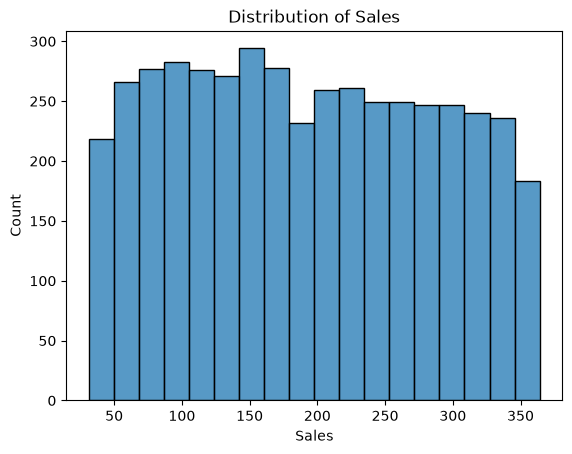

In [10]:
##visualization
fig = sns.histplot(data['Sales'])

fig.set_title('Distribution of Sales');

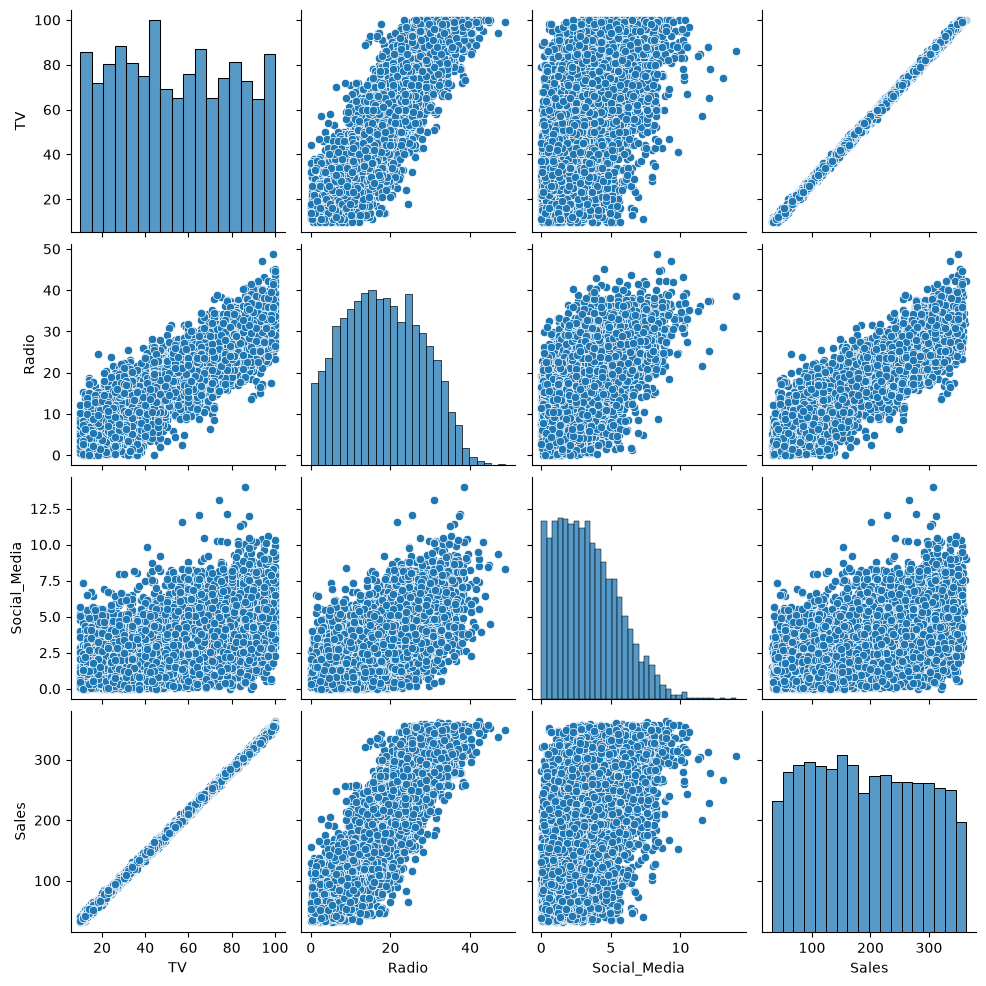

In [11]:
###model building
sns.pairplot(data);

In [13]:
# Define the OLS formula
ols_formula = 'Sales ~ TV'

OLS = ols(formula = ols_formula, data = data)

model = OLS.fit()


model_results = model.summary()

model_results

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 4.527e+06
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:31:10   Log-Likelihood:                -11393.
No. Observations:                4556   AIC:                         2.279e+04
Df Residuals:                    4554   BIC:                         2.280e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1263      0.101     -1.257      0.209      -0.323       0.071
TV             3.5614      0.002   2127.776      0.000       3.558       3.565
==============================================================================
Omnibus:                        0.051   Durbin-Watson:                   2.002
Prob(Omnibus):                  0.975   Jarque-Bera (JB):                0.030
Skew:                           0.001   Prob(JB):                        0.985
Kurtosis:                       3.012   Cond. No.                         138.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

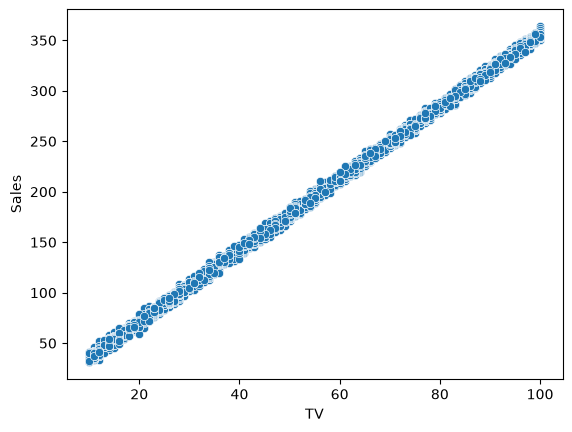

In [17]:
sns.scatterplot(x = data['TV'], y = data['Sales']);  ##compare x and y sales   ###liearity

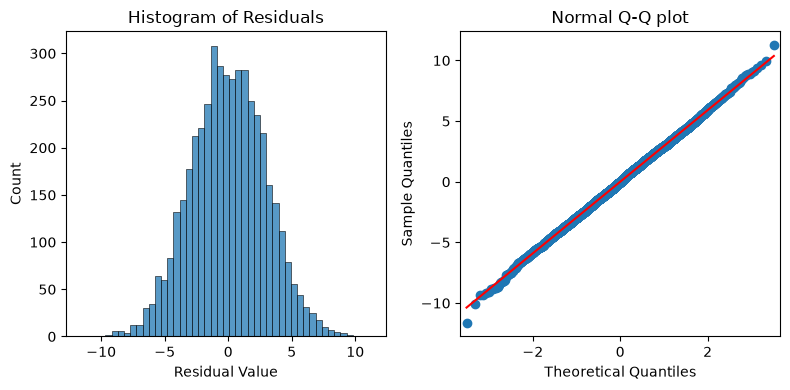

In [18]:
residuals = model.resid ##calculate residual

fig, axes = plt.subplots(1, 2, figsize = (8,4))    ###normality

sns.histplot(residuals, ax=axes[0])

axes[0].set_xlabel("Residual Value")

axes[0].set_title("Histogram of Residuals")

sm.qqplot(residuals, line='s',ax = axes[1])

axes[1].set_title("Normal Q-Q plot")

plt.tight_layout()


plt.show()

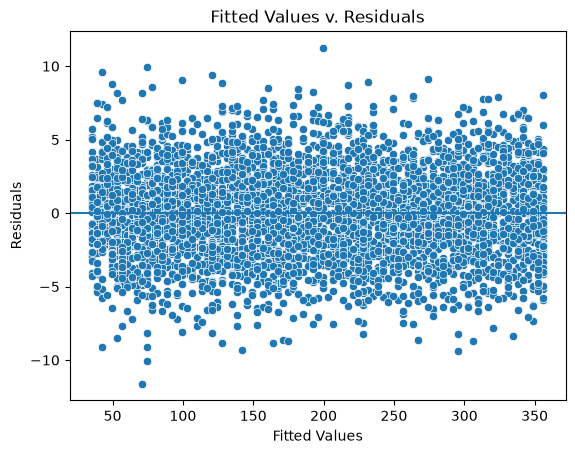

In [19]:
fig = sns.scatterplot(x = model.fittedvalues, y = model.resid) ###homosceddasticity


fig.set_xlabel("Fitted Values")


fig.set_ylabel("Residuals")


fig.set_title("Fitted Values v. Residuals")
 

fig.axhline(0)


plt.show()

In [20]:
##result
model_results

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                 4.527e+06
Date:                Thu, 15 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:31:10   Log-Likelihood:                -11393.
No. Observations:                4556   AIC:                         2.279e+04
Df Residuals:                    4554   BIC:                         2.280e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1263      0.101     -1.257      0.209      -0.323       0.071
TV             3.5614      0.002   2127.776      0.000       3.558       3.565
==============================================================================
Omnibus:                        0.051   Durbin-Watson:                   2.002
Prob(Omnibus):                  0.975   Jarque-Bera (JB):                0.030
Skew:                           0.001   Prob(JB):                        0.985
Kurtosis:                       3.012   Cond. No.                         138.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""